<a href="https://colab.research.google.com/github/tkach3nkoo/MN/blob/main/%D0%9B%D0%A06_%D0%A2%D0%BA%D0%B0%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B3%D1%80%D1%83%D0%BF%D0%B0_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [30]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

**Завантаження датасету.** Якщо CSV лежить поруч із блокнотом, використовується локальний файл. Інакше датасет завантажується з Kaggle через `kagglehub` (потрібний інтернет).

In [31]:
from pathlib import Path
csv_path = Path("diabetes_prediction_dataset.csv")
if not csv_path.exists():
    try:
        import kagglehub
    except ImportError:
        %pip -q install kagglehub
        import kagglehub
    dataset_dir = Path(kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset"))
    matches = list(dataset_dir.rglob("diabetes_prediction_dataset.csv"))
    if not matches:
        raise FileNotFoundError("У завантаженому датасеті Kaggle не знайдено diabetes_prediction_dataset.csv")
    csv_path = matches[0]
df = pd.read_csv(csv_path)
required_columns = {"gender", "age", "hypertension", "heart_disease", "smoking_history", "bmi", "HbA1c_level", "blood_glucose_level", "diabetes"}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"У датасеті відсутні стовпці: {sorted(missing)}")
print(f"Файл: {csv_path} | Розмір: {df.shape[0]:,} × {df.shape[1]}")
display(df.head())

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Файл: /kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv | Розмір: 100,000 × 9


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
# Дані вже завантажені у попередній клітинці.
display(df.head())

**Джерело даних:** [Kaggle — Diabetes Prediction Dataset](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset). Альтернативне завантаження через Kaggle не потрібне.

In [32]:
# Використовується один спосіб завантаження даних з клітинки вище.

In [33]:
display(df.sample(5, random_state=RANDOM_STATE))

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
75721,Female,13.0,0,0,No Info,20.82,5.8,126,0
80184,Female,3.0,0,0,No Info,21.00,5.0,145,0
19864,Male,63.0,0,0,former,25.32,3.5,200,0
76699,Female,2.0,0,0,never,17.43,6.1,126,0
92991,Female,33.0,0,0,not current,40.08,6.2,200,1


Вивести інформацію про датасет

In [ ]:
df.info()
print("Категоріальні ознаки: gender, smoking_history; інші — числові.")

Провести дослідження категоріальних ознак

In [34]:
print(df["gender"].value_counts(dropna=False))

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [35]:
print(df["smoking_history"].value_counts(dropna=False))

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [36]:
display(df.head(10))

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


Вивести типи даних

In [37]:
print(df.dtypes)

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [38]:
print(df["diabetes"].value_counts())
print((df["diabetes"].value_counts(normalize=True)*100).round(2).astype(str)+" %")

diabetes
0    91500
1     8500
Name: count, dtype: int64
diabetes
0    91.5 %
1     8.5 %
Name: proportion, dtype: object


**Висновок:** клас `diabetes = 1` трапляється істотно рідше за клас `0`; наявний дисбаланс. Точні частки наведені вище. Для навчання використаємо SMOTE тільки на train.

Перевірити наявність пропущених даних


In [39]:
print(df.isna().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [40]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [41]:
df = df.drop_duplicates().reset_index(drop=True)
print("Після усунення дублікатів:", df.shape)

Після усунення дублікатів: (96146, 9)


In [ ]:
display(df.head())

Ще раз перевірити баланс цільової змінної

In [42]:
print(df["diabetes"].value_counts())
print((df["diabetes"].value_counts(normalize=True)*100).round(2))

diabetes
0    87664
1     8482
Name: count, dtype: int64
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


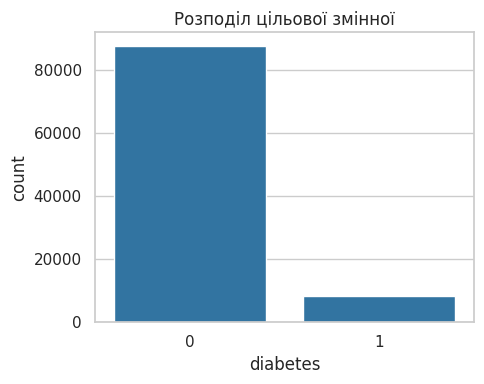

In [43]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="diabetes", color="tab:blue")
plt.title("Розподіл цільової змінної")
plt.tight_layout()
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [44]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from imblearn.over_sampling import SMOTE
from sklearn.base import clone

In [45]:
X = df.drop(columns=["diabetes"])
y = df["diabetes"].astype(int)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train_raw.shape, "Test:", X_test_raw.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [46]:
categorical_cols = ["gender", "smoking_history"]
X_train = pd.get_dummies(X_train_raw, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
assert X_train.columns.equals(X_test.columns)
print("Кількість ознак після кодування:", X_train.shape[1])

Кількість ознак після кодування: 15


In [47]:
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [48]:
train_correlations = X_train.assign(diabetes=y_train).corr(numeric_only=True)["diabetes"].drop("diabetes")
print(train_correlations.sort_values(key=abs, ascending=False).round(3))

blood_glucose_level            0.423
HbA1c_level                    0.405
age                            0.267
bmi                            0.213
hypertension                   0.199
heart_disease                  0.174
smoking_history_No Info       -0.113
smoking_history_former         0.096
gender_Male                    0.041
gender_Female                 -0.041
smoking_history_never          0.026
smoking_history_ever           0.021
smoking_history_not current    0.019
smoking_history_current        0.014
gender_Other                  -0.004
Name: diabetes, dtype: float64


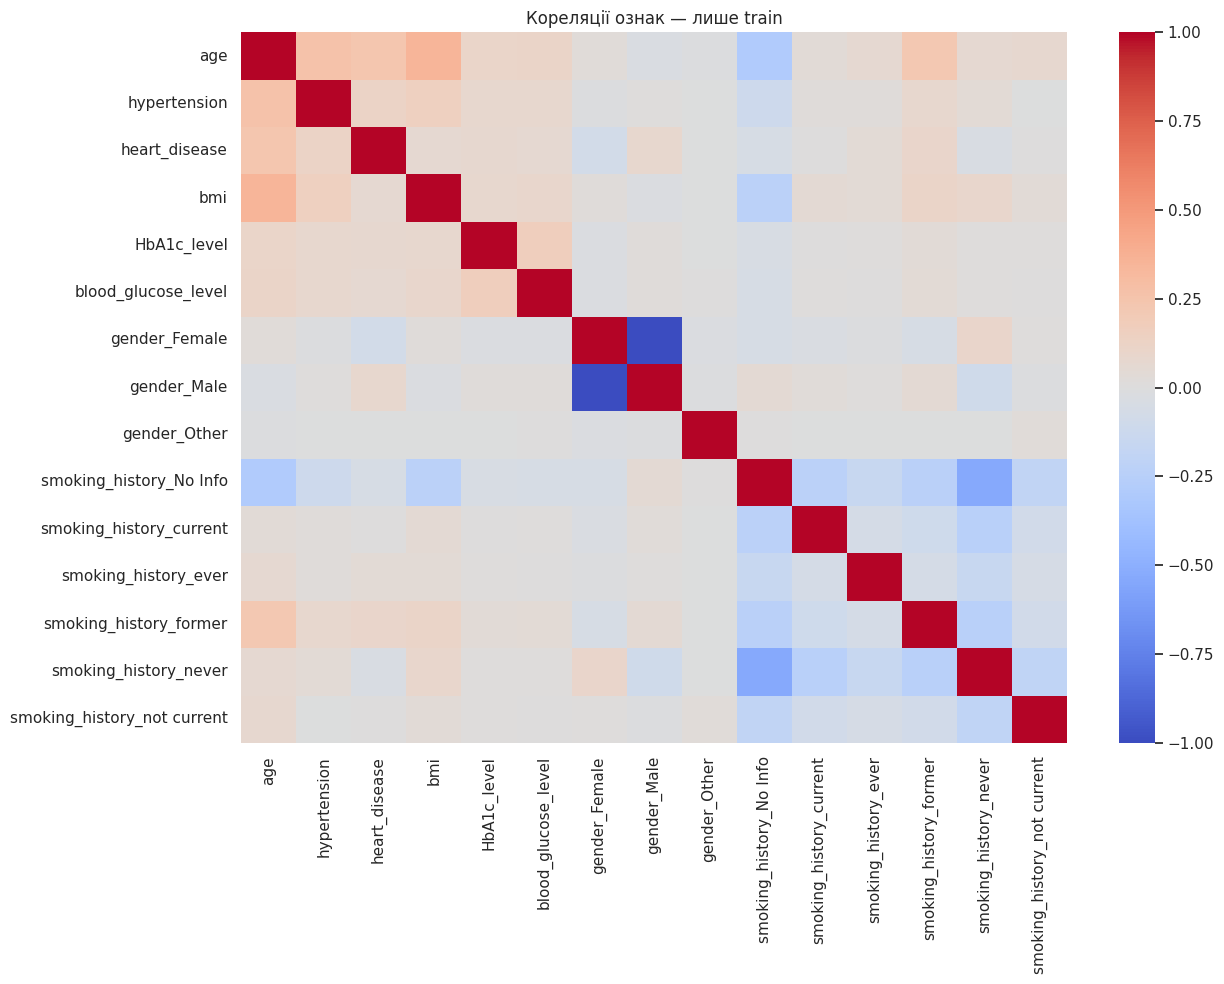

In [49]:
feature_corr = X_train.corr(numeric_only=True)
plt.figure(figsize=(13, 10))
sns.heatmap(feature_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Кореляції ознак — лише train")
plt.tight_layout()
plt.show()

**Висновок:** визначаємо найсильніші зв’язки виключно за train (таблиця й теплова карта вище). Найбільша прогностична пов’язаність очікується для HbA1c, глюкози крові та віку. Кореляція не доводить причинності; сильніші зв’язки між dummy-ознаками однієї категорії можуть виникати через взаємовиключність категорій. Без додаткової валідації ознаки не видаляємо.

Перевірити викиди **лише на навчальній вибірці**

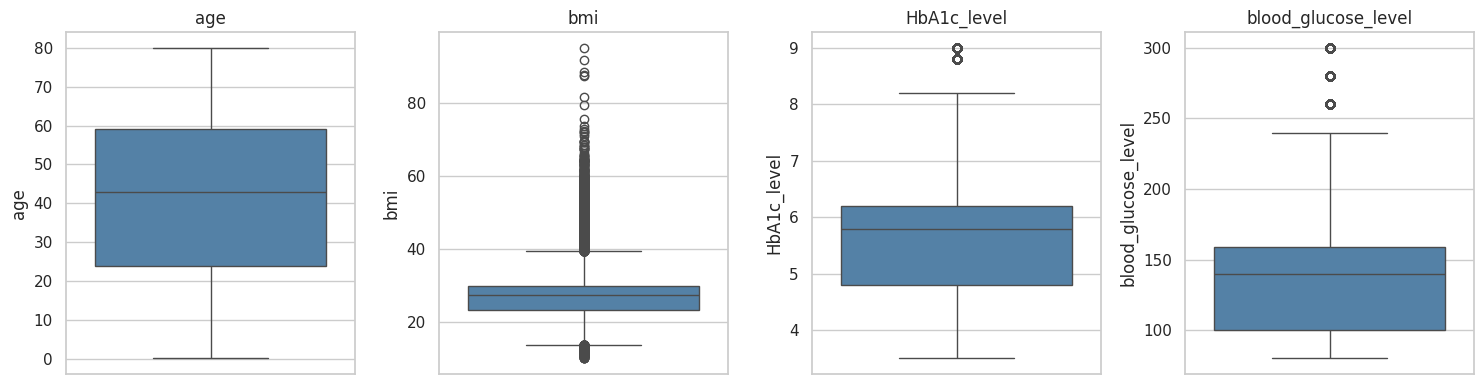

Кількість значень за межами IQR на train:
 age                       0
bmi                    4244
HbA1c_level            1041
blood_glucose_level    1598
dtype: int64


In [50]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()
q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((X_train[continuous_cols] < q1-1.5*iqr) | (X_train[continuous_cols] > q3+1.5*iqr)).sum()
print("Кількість значень за межами IQR на train:\n", outlier_counts)

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [51]:
# Приклад розрахунку меж (без видалення):
q1_bmi, q3_bmi = X_train["bmi"].quantile([0.25, 0.75])
iqr_bmi = q3_bmi - q1_bmi
print("bmi IQR boundaries:", q1_bmi - 1.5*iqr_bmi, q3_bmi + 1.5*iqr_bmi)
# X_train, y_train, X_test і y_test залишаються незмінними.

bmi IQR boundaries: 13.7 39.540000000000006


Перевірити асиметрію розподілів ознак **на train**

In [52]:
print("Асиметрія розподілів на train:\n", X_train[continuous_cols].skew().round(3))

Асиметрія розподілів на train:
 age                   -0.061
bmi                    1.005
HbA1c_level           -0.056
blood_glucose_level    0.831
dtype: float64


In [53]:
print("Пропуски у train:", int(X_train.isna().sum().sum()))
print("Пропуски у test:", int(X_test.isna().sum().sum()))

Пропуски у train: 0
Пропуски у test: 0


**Проміжний висновок:** цільова змінна незбалансована; кореляції та IQR розраховані тільки на навчальній вибірці. Значення за межами IQR не завжди є помилками вимірювання — їх не видаляємо автоматично. Тестові приклади не змінюємо й не балансуємо.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [54]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Масштабування завершено:", X_train_scaled.shape, X_test_scaled.shape)

Масштабування завершено: (76916, 15) (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [55]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)
print("До SMOTE:\n", y_train.value_counts().sort_index())
print("Після SMOTE:\n", pd.Series(y_train_bal).value_counts().sort_index())

До SMOTE:
 diabetes
0    70130
1     6786
Name: count, dtype: int64
Після SMOTE:
 diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [56]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
    "RidgeClassifier": RidgeClassifier(random_state=RANDOM_STATE),
    "SGDClassifier": SGDClassifier(random_state=RANDOM_STATE, max_iter=1500),
    "SVC": SVC(random_state=RANDOM_STATE, cache_size=512),
}

Навчаємо базові моделі та порівнюємо їх на **валідаційній частині train**. Тестова вибірка залишається для остаточної оцінки.


 ================ LogisticRegression ================
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     14027
           1       0.42      0.88      0.57      1357

    accuracy                           0.88     15384
   macro avg       0.70      0.88      0.75     15384
weighted avg       0.94      0.88      0.90     15384



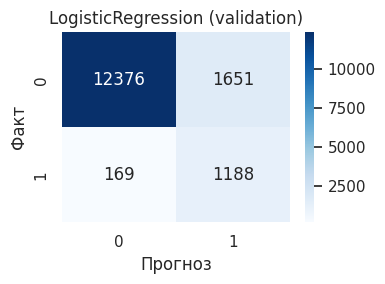


 ================ RidgeClassifier ================
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     14027
           1       0.43      0.87      0.57      1357

    accuracy                           0.89     15384
   macro avg       0.71      0.88      0.75     15384
weighted avg       0.94      0.89      0.90     15384



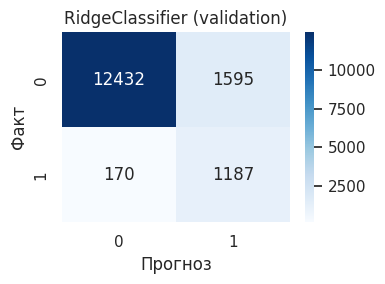


 ================ SGDClassifier ================
              precision    recall  f1-score   support

           0       0.99      0.87      0.92     14027
           1       0.39      0.89      0.54      1357

    accuracy                           0.87     15384
   macro avg       0.69      0.88      0.73     15384
weighted avg       0.94      0.87      0.89     15384



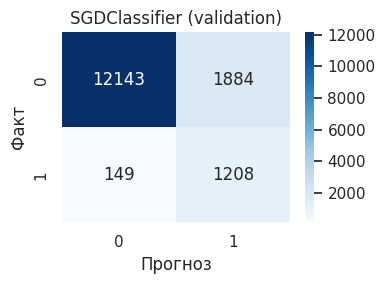


 ================ SVC ================
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     14027
           1       0.43      0.91      0.58      1357

    accuracy                           0.88     15384
   macro avg       0.71      0.90      0.76     15384
weighted avg       0.94      0.88      0.90     15384



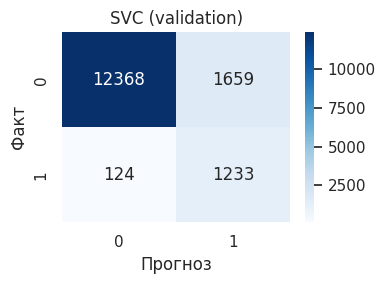

,F1 (class 1),Recall (class 1)
SVC,0.580372,0.908622
RidgeClassifier,0.573568,0.874724
LogisticRegression,0.566254,0.875461
SGDClassifier,0.543043,0.890199


In [57]:
# Відокремлюємо validation від train до масштабування та SMOTE.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)

val_scaler = StandardScaler()
X_fit_scaled = val_scaler.fit_transform(X_fit)
X_val_scaled = val_scaler.transform(X_val)

val_smote = SMOTE(random_state=RANDOM_STATE)
X_fit_bal, y_fit_bal = val_smote.fit_resample(X_fit_scaled, y_fit)

baseline_results = {}
for name, estimator in models.items():
    print("\n", "=" * 16, name, "=" * 16)
    fitted = clone(estimator)
    fitted.fit(X_fit_bal, y_fit_bal)
    pred = fitted.predict(X_val_scaled)

    baseline_results[name] = {
        "F1 (class 1)": f1_score(y_val, pred, pos_label=1, zero_division=0),
        "Recall (class 1)": recall_score(y_val, pred, pos_label=1, zero_division=0),
    }

    print(classification_report(y_val, pred, labels=[0, 1], zero_division=0))
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        confusion_matrix(y_val, pred, labels=[0, 1]),
        annot=True, fmt="d", cmap="Blues"
    )
    plt.xlabel("Прогноз")
    plt.ylabel("Факт")
    plt.title(f"{name} (validation)")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame.from_dict(baseline_results, orient="index")
        .sort_values("F1 (class 1)", ascending=False))

Оптимізувати гіперпараметри


In [58]:
param_grids = {
    "LogisticRegression": {"model__C": [0.1, 1.0], "model__solver": ["lbfgs"]},
    "RidgeClassifier": {"model__alpha": [0.1, 1.0, 10.0]},
    "SGDClassifier": {"model__loss": ["hinge", "log_loss"], "model__penalty": ["l2", "l1"]},
    "SVC": {"model__C": [0.1, 1.0], "model__kernel": ["linear", "rbf"]},
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE входять до Pipeline кожного фолду. Тестова вибірка не бере участі в підборі чи порівнянні моделей.

In [59]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [60]:
best_models, best_scores, tuning_results = {}, {}, {}
for name, estimator in models.items():
    print(f"\nПошук параметрів: {name}")
    pipeline = Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", clone(estimator)),
    ])
    search = HalvingGridSearchCV(
        pipeline,
        param_grids[name],
        cv=3,
        scoring="f1",
        factor=3,
        min_resources=300,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = float(search.best_score_)
    tuning_results[name] = {
        "CV F1": float(search.best_score_),
        "Найкращі параметри": str(search.best_params_),
    }
    print("Найкращі параметри:", search.best_params_)
    print("Середній F1 за CV:", round(search.best_score_, 4))

# Порівнюємо моделі виключно за кросвалідацією на train.
display(pd.DataFrame.from_dict(tuning_results, orient="index").sort_values("CV F1", ascending=False))


Пошук параметрів: LogisticRegression
Найкращі параметри: {'model__C': 1.0, 'model__solver': 'lbfgs'}
Середній F1 за CV: 0.6468

Пошук параметрів: RidgeClassifier
Найкращі параметри: {'model__alpha': 1.0}
Середній F1 за CV: 0.5989

Пошук параметрів: SGDClassifier
Найкращі параметри: {'model__loss': 'log_loss', 'model__penalty': 'l2'}
Середній F1 за CV: 0.5525

Пошук параметрів: SVC
Найкращі параметри: {'model__C': 1.0, 'model__kernel': 'linear'}
Середній F1 за CV: 0.578


,CV F1,Найкращі параметри
LogisticRegression,0.646825,"{'model__C': 1.0, 'model__solver': 'lbfgs'}"
RidgeClassifier,0.598938,{'model__alpha': 1.0}
SVC,0.578008,"{'model__C': 1.0, 'model__kernel': 'linear'}"
SGDClassifier,0.552530,"{'model__loss': 'log_loss', 'model__penalty': ..."


Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

Найкраща модель за CV F1: LogisticRegression
Середній F1 за CV: 0.6468
Test F1 (class 1): 0.5739
Test Recall (class 1): 0.8791
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



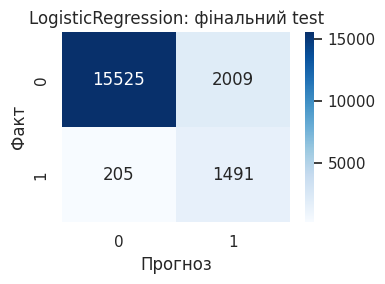

In [61]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print("Найкраща модель за CV F1:", best_name)
print("Середній F1 за CV:", round(best_scores[best_name], 4))

# Єдина фінальна оцінка обраної класичної моделі на відкладеному test.
final_pred = best_model.predict(X_test)
final_f1 = f1_score(y_test, final_pred, zero_division=0)
final_recall = recall_score(y_test, final_pred, zero_division=0)
print(f"Test F1 (class 1): {final_f1:.4f}")
print(f"Test Recall (class 1): {final_recall:.4f}")
print(classification_report(y_test, final_pred, labels=[0, 1], zero_division=0))
plt.figure(figsize=(4, 3))
sns.heatmap(confusion_matrix(y_test, final_pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues")
plt.title(f"{best_name}: фінальний test")
plt.xlabel("Прогноз")
plt.ylabel("Факт")
plt.tight_layout()
plt.show()

In [62]:
sample_indices = X_test.sample(n=10, random_state=RANDOM_STATE).index
sample_predictions = best_model.predict(X_test.loc[sample_indices])
comparison = pd.DataFrame({
    "індекс": sample_indices,
    "істинний клас": y_test.loc[sample_indices].to_numpy(),
    "передбачений клас": sample_predictions
})
display(comparison.reset_index(drop=True))

,індекс,істинний клас,передбачений клас
0,35493,0,0
1,29438,0,0
2,29287,0,1
3,11752,0,0
4,95450,0,0
5,26415,0,0
6,51899,0,0
7,67326,0,0
8,8881,0,1
9,36474,0,0


**Підсумкові висновки**

1. Розподіл `diabetes` визначає дисбаланс класів (точні частки надруковано вище).
2. Кореляції, асиметрія й викиди проаналізовані лише на навчальній вибірці.
3. Масштабування та SMOTE проводяться без використання тестової вибірки. Під час кросвалідації вони застосовуються окремо всередині кожного фолду, що запобігає витоку даних.
4. Базові моделі порівнюються на validation, оптимізовані — за середнім F1 у кросвалідації на train.
5. Найкраща оптимізована модель визначається за CV F1. Її фінальні F1 та Recall вимірюються на відкладеній тестовій вибірці один раз. Конкретні значення виводяться під час запуску.
6. XGBoost, LightGBM та CatBoost досліджуються окремо; тестові показники не використовуються для налаштування моделей.

**Обмеження:** результати залежать від реального завантаженого CSV, версій бібліотек і часу виконання SVC / підбору гіперпараметрів.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [64]:
%pip install -q catboost

In [65]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [66]:
%pip install -q xgboost lightgbm catboost


XGBoost
               precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.99      0.69      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230



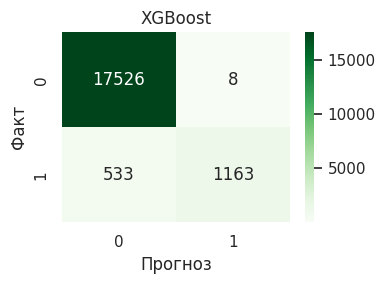


LightGBM
               precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.98      0.69      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230



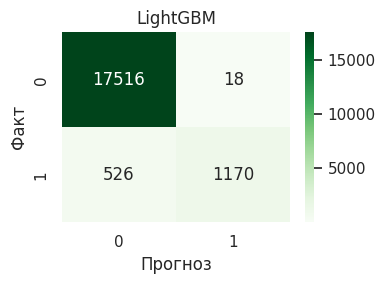


CatBoost
               precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.99      0.69      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



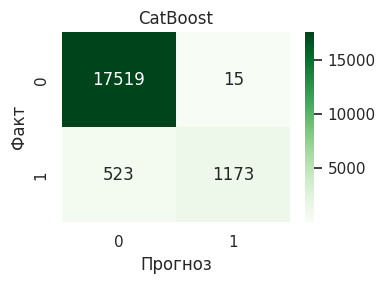

,F1 (class 1),Recall (class 1)
CatBoost,0.813454,0.691627
LightGBM,0.811373,0.689858
XGBoost,0.811301,0.685731


Примітка: додаткові ансамблі не використовуються для вибору best_model.


In [67]:
# Додаткове завдання. Для моделей потрібні пакети:
# %pip -q install xgboost lightgbm catboost
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

extra_models = {
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.08,
                              eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=150, max_depth=5, learning_rate=0.08,
                               verbose=-1, random_state=RANDOM_STATE, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=150, depth=5, learning_rate=0.08,
                                   verbose=False, random_seed=RANDOM_STATE, thread_count=-1),
}
extra_results = {}
# Для додаткового завдання показуємо незалежні оцінки на test,
# але НЕ використовуємо ці оцінки для вибору best_model чи зміни налаштувань.
for name, estimator in extra_models.items():
    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    pred = np.asarray(fitted.predict(X_test)).ravel().astype(int)
    extra_results[name] = {
        "F1 (class 1)": f1_score(y_test, pred, zero_division=0),
        "Recall (class 1)": recall_score(y_test, pred, zero_division=0),
    }
    print(f"\n{name}\n", classification_report(y_test, pred, labels=[0, 1], zero_division=0))
    plt.figure(figsize=(4, 3))
    sns.heatmap(confusion_matrix(y_test, pred, labels=[0, 1]), annot=True, fmt="d", cmap="Greens")
    plt.title(name)
    plt.xlabel("Прогноз")
    plt.ylabel("Факт")
    plt.tight_layout()
    plt.show()
display(pd.DataFrame.from_dict(extra_results, orient="index").sort_values("F1 (class 1)", ascending=False))
print("Примітка: додаткові ансамблі не використовуються для вибору best_model.")